In [2]:
from dataclasses import replace
from math import nan
import sklearn as sk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pygments.lexers import snobol

Duplicaten verwijderen en lege typemateriaal vullen als boek.
Soms is er WEL een tabel die "UNNAMED: 3" heet en soms niet. Hij is ALTIJD leeg. Verwijderen.

In [3]:
LD = pd.read_csv("OriginalDatasets/Leescatalogus_Recommender_Definitief_leesmateriaal_Jarno.csv")

str_cols = LD.select_dtypes(include=["object", "string"]).columns
LD[str_cols] = LD[str_cols].apply(lambda s: s.str.strip().str.lower())
LD = LD.drop_duplicates().reset_index(drop=True)

LD["Type materiaal"] = LD["Type materiaal"].fillna("boek")
if "Unnamed: 3" in LD.columns:
    LD = LD.drop(columns="Unnamed: 3")
LD

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,het dagboek van anne frank,anne frank,dagboek van een joods meisje dat tijdens de tw...,boek,3f,woii;onderduik,lm-0001,fictie,woii,woii; onderduik,...,verhalen,educatief media,2025,pdf,cat-00001,b1,hoog,NaN,fictie,3.4
1,blauw water,s. van der vlugt,spannende thriller waarin een vrouw wordt geco...,boek,3f,spanning;stalking,lm-0002,fictie,spanning,spanning; stalking,...,verhalen,leeswereld,2005,digitaal,cat-00002,b2,hoog,nt2,fictie,2.5
2,boer vindt vrouw,h. van der werf,"toegankelijk verhaal over liefde, relaties en ...",boek,2f,liefde;relaties,lm-0003,fictie,liefde,liefde; relaties,...,verhalen,NaN,2025,digitaal,cat-00003,b2,midden,nt2,fictie,3.8
3,cadeau voor u!,harry mulisch,bundel toegankelijke verhalen over verrassende...,boek,3f,ontmoeting;verbondenheid,lm-0004,fictie,ontmoeting,ontmoeting; verbondenheid,...,verhalen,uitgeverij noord,2018,digitaal,cat-00004,batch-2,laag,nt2,fictie,3.9
4,de biecht,mickey roorda,verhaal waarin verborgen geheimen en persoonli...,boek,2f,geheimen;schuld,lm-0005,fictie,geheimen,geheimen; schuld,...,verhalen,uitgeverij noord,NaN,online,cat-00005,b3,laag,mbo/nt2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,zorgen om studiefinanciering: 'aanpak nodig',lars dekker (nos),"criminaliteit, klimaat, media",blogpost,3f,https://www.autoriteitpersoonsgegevens.nl/arti...,lm-0279,informatief,NaN,NaN,...,verhalen,NaN,2013,online,cat-00279,b2,midden,mbo,informatief,NaN
279,wat betekent jeugdcriminaliteit voor jou?,daan de vries (nos),"werk, ai, privacy, jongeren",online artikel,3f,https://www.kijkmagazine.nl/artikel/wat-beteke...,lm-0280,informatief,NaN,NaN,...,verhalen,educatief media,NaN,online,cat-00280,b2,hoog,NaN,informatief,NaN
280,zolang het belofte duurt,vera prins,een man van veertig wordt geconfronteerd met d...,boek - roman,2f,NaN,lm-0281,fictie,NaN,NaN,...,verhalen,NaN,2005,pdf,cat-00281,b2,hoog,mbo/nt2,fictie,NaN
281,zomer zonder grens,jelle meijer,"toegankelijk verhaal over onderzoek, burgersch...",boek - thriller,2f,onderzoek;burgerschap,lm-0282,NaN,onderzoek,onderzoek; burgerschap,...,verhalen,leeswereld,1998,papier,cat-00282,batch-2,midden,NaN,NaN,NaN


# Taal
We hebben handmatig (met `.unique()`) ontdekt dat ALLES in het nederlands is. Maar alle entries zijn op verschillende manieren gemarkeerd als Nederlands. "Ned", "Nederlands", "NL"

In [4]:
LD["taal"] = LD["taal"].replace(r"^.*","Nederlands", regex=True)

# Consistentie fix
Verandert alle variaties van boeken naar : "boek"

In [5]:
# Huidige Type Materiaal
LD["Type materiaal"].unique()

<StringArray>
[           'boek',     'tijdschrift',  'krant (papier)',  'digitale krant',
 'boek - thriller',    'boek - roman',  'online artikel',     'dichtbundel',
        'blogpost']
Length: 9, dtype: str

In [6]:
LD["Type materiaal"] = LD["Type materiaal"].replace(
    r"^[Bb]oek\s?-?\s?.*?$", "boek", regex=True
)
# Controle
LD["Type materiaal"].unique()

<StringArray>
[          'boek',    'tijdschrift', 'krant (papier)', 'digitale krant',
 'online artikel',    'dichtbundel',       'blogpost']
Length: 7, dtype: str

<function matplotlib.pyplot.show(close=None, block=None)>

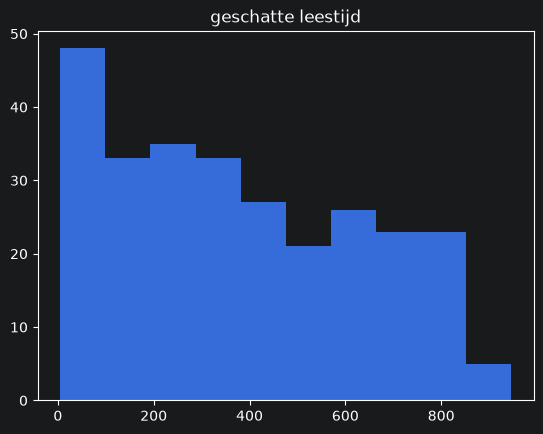

In [7]:
# plot alles van de kolom geschatte leestijd in een histogram
plt.title("geschatte leestijd")
plt.hist(LD["geschatte_leestijd_min"])
plt.show

In [8]:
LD[(LD["geschatte_leestijd_min"].isnull())]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
6,de favoriete plekken van...,floortje dessing,bekende nederlanders vertellen over locaties d...,boek,2f,reizen;herinneringen,lm-0007,fictie,reizen,reizen; herinneringen,...,vrije tijd,educatief media,2025,digitaal,cat-00007,NaN,hoog,nt2,fictie,3.4
14,floortje dessing reisverhalen,floortje dessing,verzameling reisverhalen waarin bijzondere bes...,boek,2f,reizen;cultuur,lm-0015,NaN,reizen,reizen; cultuur,...,vrije tijd,NaN,2013,online,cat-00015,b2,laag,mbo,NaN,3.7
55,voor altijd jong (mijn leven met kanker),jade kops,persoonlijk en aangrijpend verhaal over leven ...,boek,2f,ziekte;veerkracht,lm-0056,fictie,ziekte,ziekte; veerkracht,...,verhalen,leeswereld,2025,NaN,cat-00056,b1,laag,mbo,fictie,3.7
59,op zoek naar mijn pad,malala yousafzai,"inspirerend verhaal over identiteit, ambitie e...",boek,3f,identiteit;ontwikkeling,lm-0060,fictie,identiteit,identiteit; ontwikkeling,...,verhalen,uitgeverij noord,2023,digitaal,cat-00060,b2,hoog,NaN,fictie,3.6
99,the hate u give,angie thomas,"aangrijpende youngadultroman over racisme, pol...",boek,3f,NaN,lm-0100,fictie,NaN,NaN,...,verhalen,uitgeverij noord,2018,NaN,cat-00100,NaN,hoog,mbo,fictie,2.7
121,mijn naam is edino,edino van dorsten,persoonlijk verhaal over opgroeien in een uitz...,boek,2f-3f,NaN,lm-0121,fictie,NaN,NaN,...,verhalen,educatief media,2099,papier,cat-00122,b2,hoog,nt2,fictie,3.4
122,moordnacht,cis meijer,jeugdthriller waarin een spannende nacht uitlo...,boek,2f,NaN,lm-0123,fictie,NaN,NaN,...,verhalen,NaN,2025,papier,cat-00123,b1,NaN,mbo/nt2,fictie,3.6
160,droom in blauwe regenjas,ted van lieshout,"herinneringen, gevoelens, identiteit",dichtbundel,2f-3f,NaN,lm-0161,poëzie,NaN,NaN,...,verhalen,uitgeverij noord,2023,online,cat-00161,NaN,NaN,NaN,NaN,3.2
178,werk vinden in nederland,het begint met taal,"werk, solliciteren, taal leren",blogpost,2f,https://www.hetbegintmettaal.nl,lm-0179,informatief,NaN,NaN,...,verhalen,NaN,NaN,NaN,cat-00179,b3,laag,NaN,NaN,2.8


# Observatie
Er zijn geen negatieve waardes voor "geschatte leestijd". Hoeft niks te veranderen. Er zijn wel 9 rijen met een lege geschatte leestijd.
# Opschonen
Ik ga alle lege waardes van geschatte leestijd invullen met gemiddelde waarde van soort gelijke lees materiaal type. Lees niveau is niet heel handig als je een digitale article 350 minuten geeft.

In [9]:
# Vul lege geschatte leestijd met het gemiddelde van hetzelfde type materiaal
LD["geschatte_leestijd_min"] = LD["geschatte_leestijd_min"].fillna(
    LD.groupby("Type materiaal")["geschatte_leestijd_min"].transform("median")
)
# Controle
LD[(LD["geschatte_leestijd_min"].isnull())]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling


# NaN vultlen.
Alle lege waarde van genre met fictie en doelgroep met NT2
(Later opnieuw doen (misschien) met NLP)

In [10]:
LD[(LD["genre"].isnull())]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
7,de man van de bloemen,johan van caeneghem,ontroerend verhaal over een onverwachte ontmoe...,boek,2f,ontmoeting;hoop,lm-0008,NaN,ontmoeting,ontmoeting; hoop,...,verhalen,NaN,1998,papier,cat-00008,b2,laag,mbo/nt2,NaN,3.6
12,een echte man,yvonne kroonenberg,met humor onderzoekt dit boek verwachtingen ro...,boek,2f,identiteit;relaties,lm-0013,NaN,identiteit,identiteit; relaties,...,verhalen,uitgeverij noord,NaN,NaN,cat-00013,b3,NaN,nt2,NaN,3.5
14,floortje dessing reisverhalen,floortje dessing,verzameling reisverhalen waarin bijzondere bes...,boek,2f,reizen;cultuur,lm-0015,NaN,reizen,reizen; cultuur,...,vrije tijd,NaN,2013,online,cat-00015,b2,laag,mbo,NaN,3.7
30,sherlock holmes wereldverhalen,arthur conan doyle,bundel klassieke detectiveverhalen waarin sher...,boek,3f,mysterie;detective,lm-0031,NaN,mysterie,mysterie; detective,...,verhalen,leeswereld,NaN,online,cat-00031,b2,hoog,NaN,NaN,3.6
53,dode meisjes praten niet,sandra j. paul,thriller waarin een ogenschijnlijk afgesloten ...,boek,2f,thriller;mysterie,lm-0054,NaN,thriller,thriller; mysterie,...,verhalen,leeswereld,1998,papier,cat-00054,batch-2,midden,NaN,NaN,3.6
67,het geluid van de stilte,inez weski,"persoonlijk relaas over rechtspraak, media-aan...",boek,3f+,NaN,lm-0068,NaN,NaN,NaN,...,verhalen,leeswereld,NaN,papier,cat-00068,b3,midden,mbo,NaN,2.8
72,de strafzaak tegen willem holleeder,frank wieland,reconstructie van een van de bekendste nederla...,boek,3f,NaN,lm-0073,NaN,NaN,NaN,...,verhalen,uitgeverij noord,1998,papier,cat-00073,NaN,laag,mbo/nt2,NaN,2.6
77,latino king,bibi dumon tak,waargebeurd verhaal dat inzicht geeft in jeugd...,boek,2f,NaN,lm-0078,NaN,NaN,NaN,...,verhalen,leeswereld,NaN,digitaal,cat-00078,b1,NaN,NaN,NaN,3.1
82,het blauw van de oceaan,zoulfa katouh,"actuele roman over identiteit, discriminatie e...",boek,3f,NaN,lm-0083,NaN,NaN,NaN,...,verhalen,NaN,NaN,NaN,cat-00083,b2,laag,mbo,NaN,3.4
96,confrontaties,simone atangana bekono,"indringende roman over identiteit, woede en ze...",boek,3f+,NaN,lm-0097,NaN,NaN,NaN,...,verhalen,NaN,1998,online,cat-00097,b2,hoog,NaN,NaN,2.7


In [11]:
print(LD["Type materiaal"].unique().tolist())
print(LD["genre"].unique().tolist())

['boek', 'tijdschrift', 'krant (papier)', 'digitale krant', 'online artikel', 'dichtbundel', 'blogpost']
['fictie', nan, 'informatief', 'poëzie']


In [12]:
LD[(LD["Type materiaal"]=="blogpost") | (LD["Type materiaal"]=="online artikel")| (LD["Type materiaal"]=="krant (papier)")| (LD["Type materiaal"]=="tijdschrift")]["genre"] = LD["genre"].fillna("informatief")
LD[(LD["Type materiaal"]=="dichtbundel")]["genre"] = LD["genre"].fillna("poëzie")
LD["doelgroep"] = LD["doelgroep"].fillna("NT2")

C:\Users\jarno\AppData\Local\Temp\ipykernel_3660\4046617159.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  LD[(LD["Type materiaal"]=="blogpost") | (LD["Type materiaal"]=="online artikel")| (LD["Type materiaal"]=="krant (papier)")| (LD["Type materiaal"]=="tijdschrift")]["genre"] = LD["genre"].fillna("informatief")
C:\Users\jarno\AppData\Local\Temp\ipykernel_3660\4046617159.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chai

In [13]:
#Fix doelgroepen door verschillende varianten naar 1 te zetten
LD["doelgroep"] = LD["doelgroep"].replace("mbo", "MBO")
LD["doelgroep"] = LD["doelgroep"].replace("mbo / nt2", "MBO/NT2")
#Dit zijn (gechecked) kranten/magazines
LD["doelgroep"]=LD["doelgroep"].fillna("NT2")
LD["doelgroep"].unique()

<StringArray>
['MBO', 'mbo/nt2', 'nt2', 'NT2', 'MBO/NT2']
Length: 5, dtype: str

In [14]:
# laad alles in
LD[(LD["Themas_boek"].notnull())]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,het dagboek van anne frank,anne frank,dagboek van een joods meisje dat tijdens de tw...,boek,3f,woii;onderduik,lm-0001,fictie,woii,woii; onderduik,...,verhalen,educatief media,2025,pdf,cat-00001,b1,hoog,NaN,fictie,3.4
1,blauw water,s. van der vlugt,spannende thriller waarin een vrouw wordt geco...,boek,3f,spanning;stalking,lm-0002,fictie,spanning,spanning; stalking,...,verhalen,leeswereld,2005,digitaal,cat-00002,b2,hoog,nt2,fictie,2.5
2,boer vindt vrouw,h. van der werf,"toegankelijk verhaal over liefde, relaties en ...",boek,2f,liefde;relaties,lm-0003,fictie,liefde,liefde; relaties,...,verhalen,NaN,2025,digitaal,cat-00003,b2,midden,nt2,fictie,3.8
3,cadeau voor u!,harry mulisch,bundel toegankelijke verhalen over verrassende...,boek,3f,ontmoeting;verbondenheid,lm-0004,fictie,ontmoeting,ontmoeting; verbondenheid,...,verhalen,uitgeverij noord,2018,digitaal,cat-00004,batch-2,laag,nt2,fictie,3.9
4,de biecht,mickey roorda,verhaal waarin verborgen geheimen en persoonli...,boek,2f,geheimen;schuld,lm-0005,fictie,geheimen,geheimen; schuld,...,verhalen,uitgeverij noord,NaN,online,cat-00005,b3,laag,mbo/nt2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,digitale veiligheid in nederland: de stand van...,nos/anp,"discriminatie, wetgeving",online artikel,3f+,https://www.nos.nl/artikel/digitale-veiligheid...,lm-0275,informatief,NaN,NaN,...,verhalen,NaN,NaN,online,cat-00275,NaN,midden,mbo,informatief,NaN
278,zorgen om studiefinanciering: 'aanpak nodig',lars dekker (nos),"criminaliteit, klimaat, media",blogpost,3f,https://www.autoriteitpersoonsgegevens.nl/arti...,lm-0279,informatief,NaN,NaN,...,verhalen,NaN,2013,online,cat-00279,b2,midden,mbo,informatief,NaN
279,wat betekent jeugdcriminaliteit voor jou?,daan de vries (nos),"werk, ai, privacy, jongeren",online artikel,3f,https://www.kijkmagazine.nl/artikel/wat-beteke...,lm-0280,informatief,NaN,NaN,...,verhalen,educatief media,NaN,online,cat-00280,b2,hoog,NaN,informatief,NaN
281,zomer zonder grens,jelle meijer,"toegankelijk verhaal over onderzoek, burgersch...",boek,2f,onderzoek;burgerschap,lm-0282,NaN,onderzoek,onderzoek; burgerschap,...,verhalen,leeswereld,1998,papier,cat-00282,batch-2,midden,NaN,NaN,NaN


In [15]:
#toont alles waar niveau null is
ldExtract = LD[(LD["Niveau"].isnull())]
ldExtract

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
37,libello voor mannen,NaN,toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,NaN,NaN,lm-0038,fictie,NaN,NaN,...,verhalen,leeswereld,NaN,papier,cat-00038,NaN,hoog,NaN,fictie,2.9
38,libello voor vrouwen,NaN,toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,NaN,NaN,lm-0039,fictie,NaN,NaN,...,verhalen,uitgeverij noord,2013,papier,cat-00039,batch-2,laag,nt2,fictie,3.5
39,de startkrant,NaN,eenvoudig geschreven krant met actueel nieuws ...,krant (papier),NaN,NaN,lm-0040,fictie,NaN,NaN,...,verhalen,leeswereld,2099,papier,cat-00040,batch-2,NaN,NaN,fictie,3.3
40,de startweekkrant,NaN,wekelijkse digitale krant met begrijpelijke ar...,digitale krant,NaN,NaN,lm-0041,fictie,NaN,NaN,...,verhalen,leeswereld,NaN,digitaal,cat-00041,NaN,midden,nt2,fictie,3.1
156,"tekorten zorgpersoneel nemen sneller toe, 'hoo...",nos,"zorg, arbeidsmarkt",online artikel,NaN,https://nos.nl/artikel/2548636-tekorten-zorgpe...,lm-0157,informatief,NaN,NaN,...,verhalen,NaN,2013,pdf,cat-00157,b3,hoog,NaN,informatief,3.5
157,nieuwe generatie fysiotherapeuten valt uit na ...,sander zurhake (nos),"fysiotherapie, zorg",online artikel,NaN,https://nos.nl/artikel/2476626-nieuwe-generati...,lm-0158,informatief,NaN,NaN,...,verhalen,leeswereld,2023,online,cat-00158,batch-2,midden,nt2,informatief,3.5


# Thema Boeken
Sommige Entries hebben Thema Boeken gevuld met the BRON van een ARTIEKEL in plaats van Themas. Die veranderen we weer terug naar NaN

In [16]:
# Fixing Theme Boeken
# Articelen bron IN Themas verwijderen.
LD["Themas_boek"] = LD["Themas_boek"].replace(r"^https.*$", nan, regex=True)
LD["trefwoorden"] = LD["trefwoorden"].replace("[naturetoday.com]", nan, regex=False)

Waar we voorspellingen op kunnen maken:
- Lees complexiteit score [Voorspel gebruiker complexiteit score om boeken met gelijke scores te recommenden]
- Lees niveau []
- Geschatte Leestijd
- Doel groep

Misschien:
- Themas
- Onderwerp
- Misschien die twee samenvoegen (Dimensional reduction)

In [17]:
LD

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,het dagboek van anne frank,anne frank,dagboek van een joods meisje dat tijdens de tw...,boek,3f,woii;onderduik,lm-0001,fictie,woii,woii; onderduik,...,verhalen,educatief media,2025,pdf,cat-00001,b1,hoog,NaN,fictie,3.4
1,blauw water,s. van der vlugt,spannende thriller waarin een vrouw wordt geco...,boek,3f,spanning;stalking,lm-0002,fictie,spanning,spanning; stalking,...,verhalen,leeswereld,2005,digitaal,cat-00002,b2,hoog,nt2,fictie,2.5
2,boer vindt vrouw,h. van der werf,"toegankelijk verhaal over liefde, relaties en ...",boek,2f,liefde;relaties,lm-0003,fictie,liefde,liefde; relaties,...,verhalen,NaN,2025,digitaal,cat-00003,b2,midden,nt2,fictie,3.8
3,cadeau voor u!,harry mulisch,bundel toegankelijke verhalen over verrassende...,boek,3f,ontmoeting;verbondenheid,lm-0004,fictie,ontmoeting,ontmoeting; verbondenheid,...,verhalen,uitgeverij noord,2018,digitaal,cat-00004,batch-2,laag,nt2,fictie,3.9
4,de biecht,mickey roorda,verhaal waarin verborgen geheimen en persoonli...,boek,2f,geheimen;schuld,lm-0005,fictie,geheimen,geheimen; schuld,...,verhalen,uitgeverij noord,NaN,online,cat-00005,b3,laag,mbo/nt2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,zorgen om studiefinanciering: 'aanpak nodig',lars dekker (nos),"criminaliteit, klimaat, media",blogpost,3f,NaN,lm-0279,informatief,NaN,NaN,...,verhalen,NaN,2013,online,cat-00279,b2,midden,mbo,informatief,NaN
279,wat betekent jeugdcriminaliteit voor jou?,daan de vries (nos),"werk, ai, privacy, jongeren",online artikel,3f,NaN,lm-0280,informatief,NaN,NaN,...,verhalen,educatief media,NaN,online,cat-00280,b2,hoog,NaN,informatief,NaN
280,zolang het belofte duurt,vera prins,een man van veertig wordt geconfronteerd met d...,boek,2f,NaN,lm-0281,fictie,NaN,NaN,...,verhalen,NaN,2005,pdf,cat-00281,b2,hoog,mbo/nt2,fictie,NaN
281,zomer zonder grens,jelle meijer,"toegankelijk verhaal over onderzoek, burgersch...",boek,2f,onderzoek;burgerschap,lm-0282,NaN,onderzoek,onderzoek; burgerschap,...,verhalen,leeswereld,1998,papier,cat-00282,batch-2,midden,NaN,NaN,NaN


# Interesse cluster
Verhalen en VERHALEN

In [18]:
LD["interessecluster"].unique()

<StringArray>
['verhalen', 'vrije tijd', 'maatschappij']
Length: 3, dtype: str

In [19]:
LD["interessecluster"] = LD["interessecluster"].replace("VERHALEN", "verhalen")

# Beschikbaar Formaat
Papier en papier
Online en online

In [20]:
# Fix: Online, online, Papier, papier
LD["beschikbaar_formaat"] = LD["beschikbaar_formaat"].replace(r"^[Oo]nline$", "Online", regex=True)
LD["beschikbaar_formaat"] = LD["beschikbaar_formaat"].replace(r"^[Pp]apier$", "Papier", regex=True)

In [21]:
LD["beschikbaar_formaat"].unique()

<StringArray>
['pdf', 'digitaal', 'Online', 'Papier', nan]
Length: 5, dtype: str

In [22]:
LD

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,het dagboek van anne frank,anne frank,dagboek van een joods meisje dat tijdens de tw...,boek,3f,woii;onderduik,lm-0001,fictie,woii,woii; onderduik,...,verhalen,educatief media,2025,pdf,cat-00001,b1,hoog,NaN,fictie,3.4
1,blauw water,s. van der vlugt,spannende thriller waarin een vrouw wordt geco...,boek,3f,spanning;stalking,lm-0002,fictie,spanning,spanning; stalking,...,verhalen,leeswereld,2005,digitaal,cat-00002,b2,hoog,nt2,fictie,2.5
2,boer vindt vrouw,h. van der werf,"toegankelijk verhaal over liefde, relaties en ...",boek,2f,liefde;relaties,lm-0003,fictie,liefde,liefde; relaties,...,verhalen,NaN,2025,digitaal,cat-00003,b2,midden,nt2,fictie,3.8
3,cadeau voor u!,harry mulisch,bundel toegankelijke verhalen over verrassende...,boek,3f,ontmoeting;verbondenheid,lm-0004,fictie,ontmoeting,ontmoeting; verbondenheid,...,verhalen,uitgeverij noord,2018,digitaal,cat-00004,batch-2,laag,nt2,fictie,3.9
4,de biecht,mickey roorda,verhaal waarin verborgen geheimen en persoonli...,boek,2f,geheimen;schuld,lm-0005,fictie,geheimen,geheimen; schuld,...,verhalen,uitgeverij noord,NaN,Online,cat-00005,b3,laag,mbo/nt2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,zorgen om studiefinanciering: 'aanpak nodig',lars dekker (nos),"criminaliteit, klimaat, media",blogpost,3f,NaN,lm-0279,informatief,NaN,NaN,...,verhalen,NaN,2013,Online,cat-00279,b2,midden,mbo,informatief,NaN
279,wat betekent jeugdcriminaliteit voor jou?,daan de vries (nos),"werk, ai, privacy, jongeren",online artikel,3f,NaN,lm-0280,informatief,NaN,NaN,...,verhalen,educatief media,NaN,Online,cat-00280,b2,hoog,NaN,informatief,NaN
280,zolang het belofte duurt,vera prins,een man van veertig wordt geconfronteerd met d...,boek,2f,NaN,lm-0281,fictie,NaN,NaN,...,verhalen,NaN,2005,pdf,cat-00281,b2,hoog,mbo/nt2,fictie,NaN
281,zomer zonder grens,jelle meijer,"toegankelijk verhaal over onderzoek, burgersch...",boek,2f,onderzoek;burgerschap,lm-0282,NaN,onderzoek,onderzoek; burgerschap,...,verhalen,leeswereld,1998,Papier,cat-00282,batch-2,midden,NaN,NaN,NaN


Trainen op Aantal paginas.

In [23]:
# 0 of negatief aantal pagina's is onmogelijk -> behandel als ontbrekend
LD.loc[LD["aantal_paginas"] <= 0, "aantal_paginas"] = nan
# Voor training: alleen rijen met een geldig aantal pagina's (minimaal 1)
LD_paginas = LD.dropna(subset=["aantal_paginas"])
# Controle
LD_paginas[(LD_paginas["aantal_paginas"].isnull()) | (LD_paginas["aantal_paginas"] < 1)]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X_Data = LD_paginas[["geschatte_leestijd_min"]]
Y_Data = LD_paginas[["aantal_paginas"]]
X_train, X_test, y_train, y_test = train_test_split(X_Data, Y_Data, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
LR = sk.linear_model.LinearRegression()
LR.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[72.47]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[185.31]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[14.28]


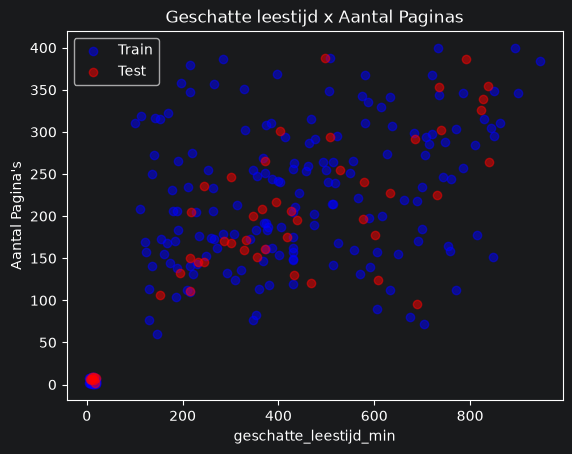

In [26]:
plt.scatter(X_train["geschatte_leestijd_min"], y_train, color='blue', alpha=0.5, label='Train')
plt.scatter(X_test["geschatte_leestijd_min"], y_test, color='red', alpha=0.5, label='Test')
plt.xlabel("geschatte_leestijd_min")
plt.ylabel("Aantal Pagina's")
plt.title("Geschatte leestijd x Aantal Paginas")
plt.legend()
plt.show()

# K-Means clustering
Clusteren op dezelfde features als de lineaire regressie: geschatte leestijd en aantal pagina's.
Eerst schalen, anders domineert leestijd (grotere getallen) de afstand.

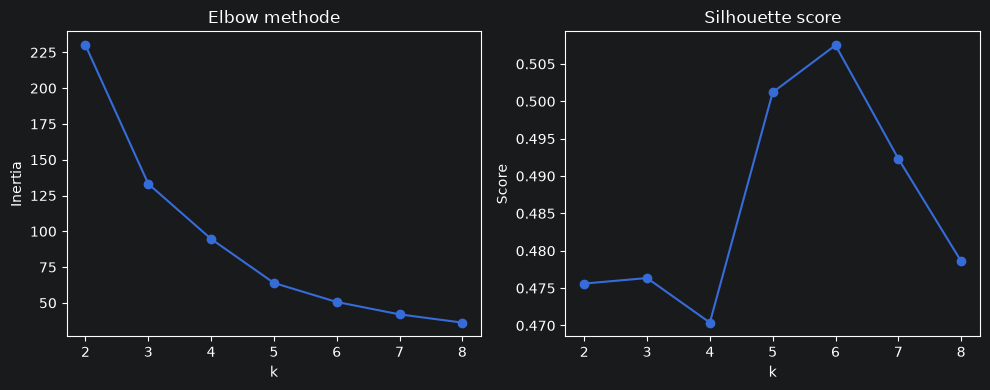

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

KM_features = ["geschatte_leestijd_min", "aantal_paginas"]
KM_scaler = StandardScaler()
KM_X = KM_scaler.fit_transform(LD_paginas[KM_features])

# Elbow + silhouette om het aantal clusters (k) te kiezen
k_range = range(2, 9)
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(KM_X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(KM_X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(k_range, inertias, marker="o")
ax1.set_title("Elbow methode")
ax1.set_xlabel("k")
ax1.set_ylabel("Inertia")
ax2.plot(k_range, silhouettes, marker="o")
ax2.set_title("Silhouette score")
ax2.set_xlabel("k")
ax2.set_ylabel("Score")
plt.tight_layout()
plt.show()

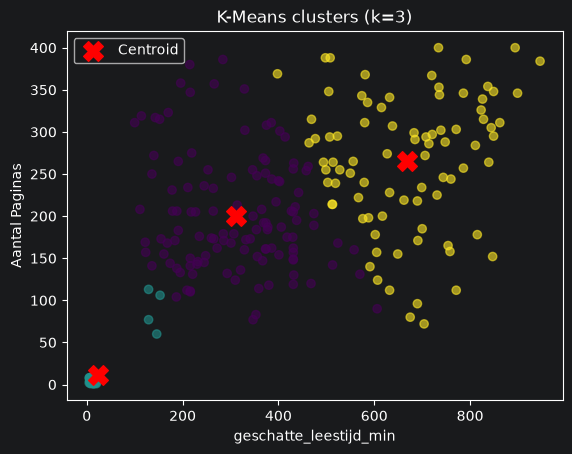

In [28]:
# k=3: duidelijke knik in de elbow, silhouette blijft ongeveer gelijk bij hogere k
KM = KMeans(n_clusters=3, n_init=10, random_state=42)
LD_paginas = LD_paginas.copy()
LD_paginas["cluster"] = KM.fit_predict(KM_X)

centers = KM_scaler.inverse_transform(KM.cluster_centers_)
plt.scatter(LD_paginas["geschatte_leestijd_min"], LD_paginas["aantal_paginas"],
            c=LD_paginas["cluster"], cmap="viridis", alpha=0.6)
plt.scatter(centers[:, 0], centers[:, 1], color="red", marker="X", s=200, label="Centroid")
plt.xlabel("geschatte_leestijd_min")
plt.ylabel("Aantal Paginas")
plt.title("K-Means clusters (k=3)")
plt.legend()
plt.show()

In [29]:
# Wat zit er in elk cluster?
LD_paginas.groupby("cluster")[KM_features].agg(["mean", "count"])

geschatte_leestijd_min       aantal_paginas      
                          mean count           mean count
cluster                                                  
0                   311.938017   121     200.611570   121
1                    22.800000    50      11.860000    50
2                   668.773810    84     265.559524    84

In [30]:
pd.crosstab(LD_paginas["cluster"], LD_paginas["Type materiaal"])

Type materiaal,blogpost,boek,dichtbundel,digitale krant,krant (papier),online artikel,tijdschrift
cluster,,,,,,,
0,0,107,11,1,1,0,1
1,14,4,0,0,0,32,0
2,0,74,9,0,0,0,1


In [31]:
LD[['Korte omschrijving',"onderwerp",'genre','Themas_boek']]
LD["Combine"] = LD["Korte omschrijving"].str.cat(LD[["onderwerp",'genre','trefwoorden','Themas_boek']], sep=" ", na_rep="")

In [32]:
LD[['trefwoorden','Themas_boek']]

,trefwoorden,Themas_boek
0,woii; onderduik,woii;onderduik
1,spanning; stalking,spanning;stalking
2,liefde; relaties,liefde;relaties
3,ontmoeting; verbondenheid,ontmoeting;verbondenheid
4,geheimen; schuld,geheimen;schuld
...,...,...
278,NaN,NaN
279,NaN,NaN
280,NaN,NaN
281,onderzoek; burgerschap,onderzoek;burgerschap


# Opmerkingen
Ontbrekende waardes in alle collomen behalve korte omschrijving.
Relevante informatie in Trefwoorden/Thema's boek + Onderwerp en Korte omschrijving
Trefwoorden en THemas boek hebben dezelfde soort data maar Thema's boek heeft een andere format (whitespace achter de puntcoma). Dit is nadat we de URLS eruit hebben gehaald.
Combineren. NaN met Whitespace invullen

In [33]:
LD[['Korte omschrijving',"onderwerp",'genre','trefwoorden','Themas_boek', "Combine"]]

,Korte omschrijving,onderwerp,genre,trefwoorden,Themas_boek,Combine
0,dagboek van een joods meisje dat tijdens de tw...,woii,fictie,woii; onderduik,woii;onderduik,dagboek van een joods meisje dat tijdens de tw...
1,spannende thriller waarin een vrouw wordt geco...,spanning,fictie,spanning; stalking,spanning;stalking,spannende thriller waarin een vrouw wordt geco...
2,"toegankelijk verhaal over liefde, relaties en ...",liefde,fictie,liefde; relaties,liefde;relaties,"toegankelijk verhaal over liefde, relaties en ..."
3,bundel toegankelijke verhalen over verrassende...,ontmoeting,fictie,ontmoeting; verbondenheid,ontmoeting;verbondenheid,bundel toegankelijke verhalen over verrassende...
4,verhaal waarin verborgen geheimen en persoonli...,geheimen,fictie,geheimen; schuld,geheimen;schuld,verhaal waarin verborgen geheimen en persoonli...
...,...,...,...,...,...,...
278,"criminaliteit, klimaat, media",NaN,informatief,NaN,NaN,"criminaliteit, klimaat, media informatief"
279,"werk, ai, privacy, jongeren",NaN,informatief,NaN,NaN,"werk, ai, privacy, jongeren informatief"
280,een man van veertig wordt geconfronteerd met d...,NaN,fictie,NaN,NaN,een man van veertig wordt geconfronteerd met d...
281,"toegankelijk verhaal over onderzoek, burgersch...",onderzoek,NaN,onderzoek; burgerschap,onderzoek;burgerschap,"toegankelijk verhaal over onderzoek, burgersch..."


***
Interactie X Leesmaterial Combineren

Nog niet besloten hier iets mee te doen.

In [34]:
RI = pd.read_csv("OriginalDatasets/Recommender_Interacties.csv")
RI

,interactie_id,student_id,cataloguscode,interactietype,beoordeling,leespercentage,leestijd_min,datum
0,I00001,S001,CAT-00223,opgeslagen,4.0,88%,305,2026-01-17
1,I00002,S001,CAT-00253,bekeken,3.0,42%,93,2026-08-24
2,I00003,S001,CAT-00055,opgeslagen,4.0,84%,299,2026-10-14
3,I00004,S001,CAT-00266,gelezen,4.0,82%,235,2026-05-04
4,I00005,S001,CAT-00262,niet_afgemaakt,2.0,14%,2,2026-02-19
...,...,...,...,...,...,...,...,...
1995,I01996,S100,CAT-00030,gelezen,4.0,99%,261,2026-04-30
1996,I01997,S100,CAT-00250,niet_afgemaakt,3.0,60%,98,2026-07-16
1997,I01998,S100,CAT-00066,gelezen,4.0,96%,698,2026-09-03
1998,I01999,S100,CAT-00009,bekeken,NaN,56%,318,2026-01-08


In [35]:
merged = RI.merge(LD, on="cataloguscode", how="left")

In [36]:
merged

,interactie_id,student_id,cataloguscode,interactietype,beoordeling,leespercentage,leestijd_min,datum,Titel,Auteur,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling,Combine
0,I00001,S001,CAT-00223,opgeslagen,4.0,88%,305,2026-01-17,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,I00002,S001,CAT-00253,bekeken,3.0,42%,93,2026-08-24,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,I00003,S001,CAT-00055,opgeslagen,4.0,84%,299,2026-10-14,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,I00004,S001,CAT-00266,gelezen,4.0,82%,235,2026-05-04,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,I00005,S001,CAT-00262,niet_afgemaakt,2.0,14%,2,2026-02-19,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,I01996,S100,CAT-00030,gelezen,4.0,99%,261,2026-04-30,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1996,I01997,S100,CAT-00250,niet_afgemaakt,3.0,60%,98,2026-07-16,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1997,I01998,S100,CAT-00066,gelezen,4.0,96%,698,2026-09-03,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1998,I01999,S100,CAT-00009,bekeken,NaN,56%,318,2026-01-08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# NLP
- Normalization
- Tokenization
- Stopword removal
- Stemming
- Lemmatization
- POS Tagging

In [37]:
LD["Combine"]

0      dagboek van een joods meisje dat tijdens de tw...
1      spannende thriller waarin een vrouw wordt geco...
2      toegankelijk verhaal over liefde, relaties en ...
3      bundel toegankelijke verhalen over verrassende...
4      verhaal waarin verborgen geheimen en persoonli...
                             ...                        
278         criminaliteit, klimaat, media  informatief  
279           werk, ai, privacy, jongeren  informatief  
280    een man van veertig wordt geconfronteerd met d...
281    toegankelijk verhaal over onderzoek, burgersch...
282    een moeder wordt geconfronteerd met doorzetten...
Name: Combine, Length: 283, dtype: str

In [55]:
LD_lower_string = LD["Combine"].str.lower()
print(LD["Combine"])

0      dagboek van een joods meisje dat tijdens de tw...
1      spannende thriller waarin een vrouw wordt geco...
2      toegankelijk verhaal over liefde, relaties en ...
3      bundel toegankelijke verhalen over verrassende...
4      verhaal waarin verborgen geheimen en persoonli...
                             ...                        
278         criminaliteit, klimaat, media  informatief  
279           werk, ai, privacy, jongeren  informatief  
280    een man van veertig wordt geconfronteerd met d...
281    toegankelijk verhaal over onderzoek, burgersch...
282    een moeder wordt geconfronteerd met doorzetten...
Name: Combine, Length: 283, dtype: str


In [61]:
import re
LD_no_number = LD_lower_string.replace(r"\d+", "",  regex=True)
print(LD_no_number)

0      dagboek van een joods meisje dat tijdens de tw...
1      spannende thriller waarin een vrouw wordt geco...
2      toegankelijk verhaal over liefde, relaties en ...
3      bundel toegankelijke verhalen over verrassende...
4      verhaal waarin verborgen geheimen en persoonli...
                             ...                        
278         criminaliteit, klimaat, media  informatief  
279           werk, ai, privacy, jongeren  informatief  
280    een man van veertig wordt geconfronteerd met d...
281    toegankelijk verhaal over onderzoek, burgersch...
282    een moeder wordt geconfronteerd met doorzetten...
Name: Combine, Length: 283, dtype: str


In [63]:
LD_no_punc = LD_no_number.str.replace(r'[^\w\s]', '', regex=True)
print(LD_no_punc)

0      dagboek van een joods meisje dat tijdens de tw...
1      spannende thriller waarin een vrouw wordt geco...
2      toegankelijk verhaal over liefde relaties en d...
3      bundel toegankelijke verhalen over verrassende...
4      verhaal waarin verborgen geheimen en persoonli...
                             ...                        
278           criminaliteit klimaat media  informatief  
279              werk ai privacy jongeren  informatief  
280    een man van veertig wordt geconfronteerd met d...
281    toegankelijk verhaal over onderzoek burgerscha...
282    een moeder wordt geconfronteerd met doorzetten...
Name: Combine, Length: 283, dtype: str


In [64]:
LD_no_wspace = LD_no_punc.str.strip()
print(LD_no_wspace)

0      dagboek van een joods meisje dat tijdens de tw...
1      spannende thriller waarin een vrouw wordt geco...
2      toegankelijk verhaal over liefde relaties en d...
3      bundel toegankelijke verhalen over verrassende...
4      verhaal waarin verborgen geheimen en persoonli...
                             ...                        
278             criminaliteit klimaat media  informatief
279                werk ai privacy jongeren  informatief
280    een man van veertig wordt geconfronteerd met d...
281    toegankelijk verhaal over onderzoek burgerscha...
282    een moeder wordt geconfronteerd met doorzetten...
Name: Combine, Length: 283, dtype: str


In [68]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('dutch'))

LD_no_stopwords = LD_no_wspace.apply(
    lambda tekst: " ".join([w for w in tekst.split() if w not in stop_words])
)
print(LD_no_stopwords)

0      dagboek joods meisje tijdens tweede wereldoorl...
1      spannende thriller waarin vrouw geconfronteerd...
2      toegankelijk verhaal liefde relaties zoektocht...
3      bundel toegankelijke verhalen verrassende ontm...
4      verhaal waarin verborgen geheimen persoonlijke...
                             ...                        
278              criminaliteit klimaat media informatief
279                 werk ai privacy jongeren informatief
280    man veertig geconfronteerd doorzetten keuzes m...
281    toegankelijk verhaal onderzoek burgerschap zoe...
282    moeder geconfronteerd doorzetten keuzes maken ...
Name: Combine, Length: 283, dtype: str


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jarno\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [69]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize

LD_tokens = LD_no_stopwords.apply(word_tokenize)
print(LD_tokens)

0      [dagboek, joods, meisje, tijdens, tweede, were...
1      [spannende, thriller, waarin, vrouw, geconfron...
2      [toegankelijk, verhaal, liefde, relaties, zoek...
3      [bundel, toegankelijke, verhalen, verrassende,...
4      [verhaal, waarin, verborgen, geheimen, persoon...
                             ...                        
278         [criminaliteit, klimaat, media, informatief]
279           [werk, ai, privacy, jongeren, informatief]
280    [man, veertig, geconfronteerd, doorzetten, keu...
281    [toegankelijk, verhaal, onderzoek, burgerschap...
282    [moeder, geconfronteerd, doorzetten, keuzes, m...
Name: Combine, Length: 283, dtype: object


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\jarno\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jarno\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jarno\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [73]:
import spacy
import pandas as pd

nlp = spacy.load("nl_core_news_sm", disable=["parser", "ner"])

docs = nlp.pipe(LD_no_stopwords, batch_size=50)
LD_lemmas = pd.Series(
    [[token.lemma_ for token in doc] for doc in docs],
    index=LD_no_stopwords.index
)
print(LD_lemmas)

0      [dagboek, joods, meisje, tijdens, twee, Wereld...
1      [spannend, thriller, waarin, vrouw, confronter...
2      [toegankelijk, verhaal, liefde, relatie, zoekt...
3      [bundel, toegankelijk, verhaal, verrassen, ont...
4      [verhaal, waarin, verbergen, geheim, persoonli...
                             ...                        
278        [criminaliteit, klimaat, medium, informatief]
279               [werk, ai, privacy, jong, informatief]
280    [man, veertig, confronteren, doorzetten, keuze...
281    [toegankelijk, verhaal, onderzoek, burgerschap...
282    [moeder, confronteren, doorzetten, keuze, make...
Length: 283, dtype: object


In [75]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Lemma's als één string per rij
LD["lemma_text"] = LD_lemmas.apply(lambda tokens: " ".join(tokens))

# N-grams (unigrams + bigrams)
vectorizer = CountVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2)
X = vectorizer.fit_transform(LD["lemma_text"])

# Resultaat bekijken
print(X.shape)


telling = pd.DataFrame(X.sum(axis=0), columns=vectorizer.get_feature_names_out()).T
telling.columns = ["aantal"]
print(telling.sort_values("aantal", ascending=False).head(20))

(283, 691)
              aantal
fictie           191
verhaal           81
waarin            57
liefde            56
jong              45
informatief       42
vriendschap       38
keuze             37
oorlog            37
identiteit        34
toegankelijk      34
staan             30
centraal          30
thriller          30
roman             29
maken             26
familie           26
leven             26
persoonlijk       26
humor             21


In [76]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Lemma's als één string per rij
LD["lemma_text"] = LD_lemmas.apply(lambda tokens: " ".join(tokens))

# N-grams (unigrams + bigrams)
vectorizer = CountVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2)
X = vectorizer.fit_transform(LD["lemma_text"])

# Resultaat bekijken
print(X.shape)
print(vectorizer.get_feature_names_out()[:20])

telling = pd.DataFrame(X.sum(axis=0), columns=vectorizer.get_feature_names_out()).T
telling.columns = ["aantal"]
print(telling.sort_values("aantal", ascending=False).head(20))

(283, 691)
['aangrijpen' 'aangrijpen verhaal' 'aantrekkingkracht' 'aanwijzing'
 'acceptatie' 'actueel' 'administratie' 'ai' 'ai informatief' 'ai privacy'
 'aiwetgeving' 'ambitie' 'ambitie doorzettingsvermogen' 'angst'
 'arbeidsmarken' 'arbeidsmarken cybercrim' 'arbeidsmarken informatief'
 'artikel' 'artikel gezondheid' 'auteur']
              aantal
fictie           191
verhaal           81
waarin            57
liefde            56
jong              45
informatief       42
vriendschap       38
keuze             37
oorlog            37
identiteit        34
toegankelijk      34
staan             30
centraal          30
thriller          30
roman             29
maken             26
familie           26
leven             26
persoonlijk       26
humor             21
